# Method 1: stress factors of the SOH degradation model

Xu et al. capacity-fade model with the LiPo-fitted parameters used in the evaluation (`battery_model._DEFAULT_AGING_PARAMS`, `evaluation/metrics.py`):

- half-cycle: $f_d = \tfrac{1}{2} k_{\mathrm{cyc}}\, S_\delta(\delta)\, S_\sigma(\bar\sigma)\, S_T(T)$
- calendar: $f_d = k_t\, t\, S_\sigma(\sigma)\, S_T(T)$
- $\Delta\mathrm{SOH} = \mathrm{SOH}\,(1 - e^{-f_d})$

One axes, log scale: DoD stress $S_\delta = (k_{\delta1}\delta^{k_{\delta2}} + k_{\delta3})^{-1}$, normalised to a full cycle; SOC stress $S_\sigma = e^{k_\sigma(\sigma - \sigma_{\mathrm{ref}})}$; temperature stress (top axis) $S_T = e^{k_T (T - T_{\mathrm{ref}}) T_{\mathrm{ref}}/T}$.
Output: `figures/pdf/method_1.pdf`.

In [46]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt

import envs  # noqa: F401  (sys.path for battery_model)
from battery_model import _DEFAULT_AGING_PARAMS as AP, _xu_s_sigma, _xu_s_temp

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 16, 'axes.titlesize': 16, 'axes.labelsize': 16,
    'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})
print({k: round(v, 6) for k, v in AP.items()})

{'k_sigma': 1.04, 'k_T': 0.0693, 'k_d1': 140000.0, 'k_d2': -0.501, 'k_d3': -123000.0, 'sigma_ref': 0.5, 'T_ref_k': 298.15, 'k_cyc': 12.029332, 'k_t': 0.0}


## Stress factors

In [47]:
# Xu et al. stress factors with the LiPo-fitted parameters used by the evaluation (evaluation/metrics.py):
#   half-cycle  f_d = 0.5 k_cyc S_delta(DoD) S_sigma(SOC_avg) S_T(T)
#   calendar    f_d = k_t t S_sigma(SOC) S_T(T)
def s_delta(dod):
    return 1.0 / (AP['k_d1'] * dod ** AP['k_d2'] + AP['k_d3'])


DOD = np.linspace(0.02, 1.0, 300)
SOC = np.linspace(0.0, 1.0, 300)
T_C = np.linspace(0.0, 50.0, 300)
S_D = s_delta(DOD) / s_delta(1.0)                                   # normalised to a full cycle
S_S = np.array([_xu_s_sigma(s, AP['k_sigma'], AP['sigma_ref']) for s in SOC])     # = 1 at SOC 50 %
S_T = np.array([_xu_s_temp(t + 273.15, AP['k_T'], AP['T_ref_k']) for t in T_C])   # = 1 at 25 C
T_REF_C = AP['T_ref_k'] - 273.15
for x, y, n in [(DOD, S_D, 'S_delta'), (SOC, S_S, 'S_sigma'), (T_C, S_T, 'S_T')]:
    print(f'{n}: {y[0]:.3f} -> {y[-1]:.3f}')

S_delta: 0.020 -> 1.000
S_sigma: 0.595 -> 1.682
S_T: 0.151 -> 4.945


## Figure

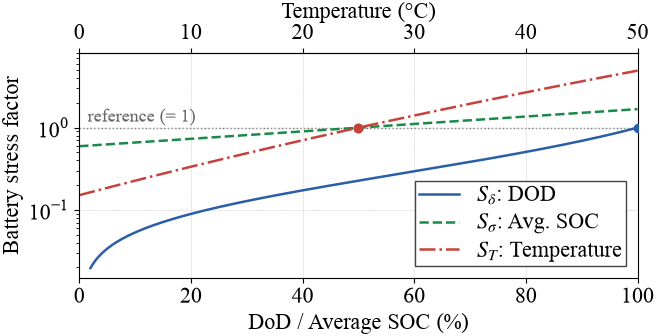

In [48]:
from matplotlib.lines import Line2D

INK, GREY = '#222222', '#666666'
LW = 1.8
# DoD and SOC on the bottom axis (0-100 %), temperature on the top axis (0-50 C mapped onto it)
T_TO_X = 100.0 / (T_C[-1] - T_C[0])
CURVES = [
    (DOD * 100, S_D, dict(color='#2a5ea8', ls='-'), r'$S_\delta$: DOD', 100.0),
    (SOC * 100, S_S, dict(color='#1a8a4a', ls='--'), r'$S_\sigma$: Avg. SOC', 100 * AP['sigma_ref']),
    ((T_C - T_C[0]) * T_TO_X, S_T, dict(color='#c8413b', ls='-.'), r'$S_T$: Temperature',
     (T_REF_C - T_C[0]) * T_TO_X),
]

fig, ax = plt.subplots(figsize=(7, 3.8))
for x, y, st, lab, xref in CURVES:
    ax.plot(x, y, lw=LW, label=lab, **st)
    ax.plot([xref], [1.0], 'o', color=st['color'], ms=6, zorder=4)
ax.axhline(1.0, color=GREY, ls=':', lw=1.0, zorder=1)
ax.text(1.5, 1.06, 'reference (= 1)', fontsize=13, color=GREY, va='bottom')
ax.set_yscale('log')
ax.set_ylim(0.015, 8)
ax.set_xlim(0, 100)
ax.set_xlabel('DoD / Average SOC (%)')
ax.set_ylabel('Battery stress factor')
top = ax.secondary_xaxis('top', functions=(lambda x: x / T_TO_X + T_C[0], lambda t: (t - T_C[0]) * T_TO_X))
top.set_xlabel('Temperature (°C)')
top.set_xticks([0, 10, 20, 30, 40, 50])
ax.legend(loc='lower right', frameon=True, fancybox=False, edgecolor='#444444', framealpha=1.0,
          handlelength=1.8, borderpad=0.2, labelspacing=0.3)
fig.tight_layout()
fig.savefig(OUT / 'method_1.pdf')
plt.show()